In [1]:
import os
import sys
from datetime import date, datetime

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")
if project_root not in sys.path:
    sys.path.insert(0, project_root)

os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"
os.environ["QUANTDATA_TRAINING_DATA"] = "!/quantdata/training"
os.environ["QUANTDATA_PROCESSING_DATA"] = "!/quantdata/processing"
os.environ["QUANTDATA_CACHE_MODE"] = "on"
os.environ["QUANTDATA_TEST_MODE"] = "0"

import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

import arbitrage
import ekf
import events
import kalman_filters
import utils

from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [2]:
df_tickers = pl.read_csv("spy_options_tickers.csv")
df_tickers

ticker,trade_count,ticker_suffix
str,i64,f64
"""O:SPY240105C00270000""",1,270000.0
"""O:SPY240105C00375000""",1,375000.0
"""O:SPY240105C00376000""",6,376000.0
"""O:SPY240105C00378000""",1,378000.0
"""O:SPY240105C00379000""",6,379000.0
…,…,…
"""O:SPY240105P00483000""",3,483000.0
"""O:SPY240105P00485000""",20,485000.0
"""O:SPY240105P00490000""",4,490000.0


In [3]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPY", trade_date)

In [4]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
Skipping O:SPY240105C00481000: 46 bad quotes (sub-tick bid×46)
Skipping O:SPY240105C00482000: 64 bad quotes (sub-tick bid×64)
Skipping O:SPY240105C00483000: 842 bad quotes (sub-tick bid×842, zero bid size×1)
Skipping O:SPY240105C00484000: 2129 bad quotes (sub-tick bid×2129, zero bid size×1)
Skipping O:SPY240105C00485000: 3888 bad quotes (sub-tick bid×3888, zero bid size×2)
O:SPY240105P00450000: dropping 1 bad quote

In [5]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.006781440 EST,null,null,null,null,479.0,true
2024-01-03 09:30:00.008294144 EST,null,null,null,null,471.0,false
2024-01-03 09:30:00.008340992 EST,null,null,null,null,479.0,true
2024-01-03 09:30:00.008425216 EST,null,null,null,null,477.0,true
2024-01-03 09:30:00.008425216 EST,null,null,null,null,478.0,true
…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.134535,0.134132,0.134856,0.134534,469.0,true
2024-01-03 16:14:59.884593152 EST,0.138451,0.132675,0.144803,0.139156,474.0,false
2024-01-03 16:14:59.884598272 EST,0.13324,0.131454,0.136743,0.133471,472.0,false


In [6]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_matched,trade_residual,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,null,NaN,NaN,null,null,479.0,true
2024-01-03 09:30:00.051 EST,null,NaN,NaN,null,null,480.0,true
2024-01-03 09:30:00.102 EST,null,NaN,NaN,null,null,463.0,false
2024-01-03 09:30:00.102 EST,null,NaN,NaN,null,null,466.0,false
2024-01-03 09:30:00.111 EST,null,NaN,NaN,0.138985,NaN,472.0,true
…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.137349,0.136552,0.137349,0.136864,0.000486,467.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,0.135461,0.000848,468.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,0.135461,0.000848,468.0,false


In [7]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,092 rows with no nulls / NaNs out of 74,092


In [8]:
df_trade_result.select(pl.col("trade_residual") ** 2).mean() * 100000

trade_residual
f64
0.835046


## Quptes smile

In [9]:
import utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [10]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

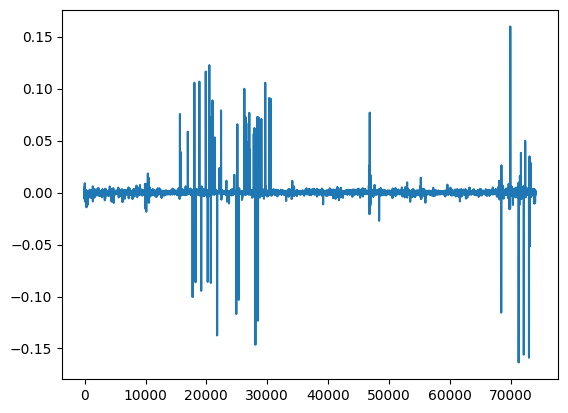

In [11]:
plt.plot(df_trade_result["trade_residual"])

In [13]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_matched,trade_residual,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.209 EST,0.144146,0.138063,0.14009,0.139077,0.005069,471.0,true
2024-01-03 09:30:00.217 EST,0.141234,0.141234,0.143378,0.14304,-0.001806,469.0,false
2024-01-03 09:30:00.225 EST,0.14009,0.138063,0.14009,0.139077,0.001013,471.0,true
2024-01-03 09:30:00.231 EST,0.131693,0.12747,0.146456,0.131201,0.000492,474.0,false
2024-01-03 09:30:00.254 EST,0.132381,0.128363,0.139425,0.13086,0.001521,480.0,true
…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.137349,0.136552,0.137349,0.136864,0.000486,467.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,0.135461,0.000848,468.0,false
2024-01-03 16:14:56.139 EST,0.13631,0.134822,0.13631,0.135461,0.000848,468.0,false


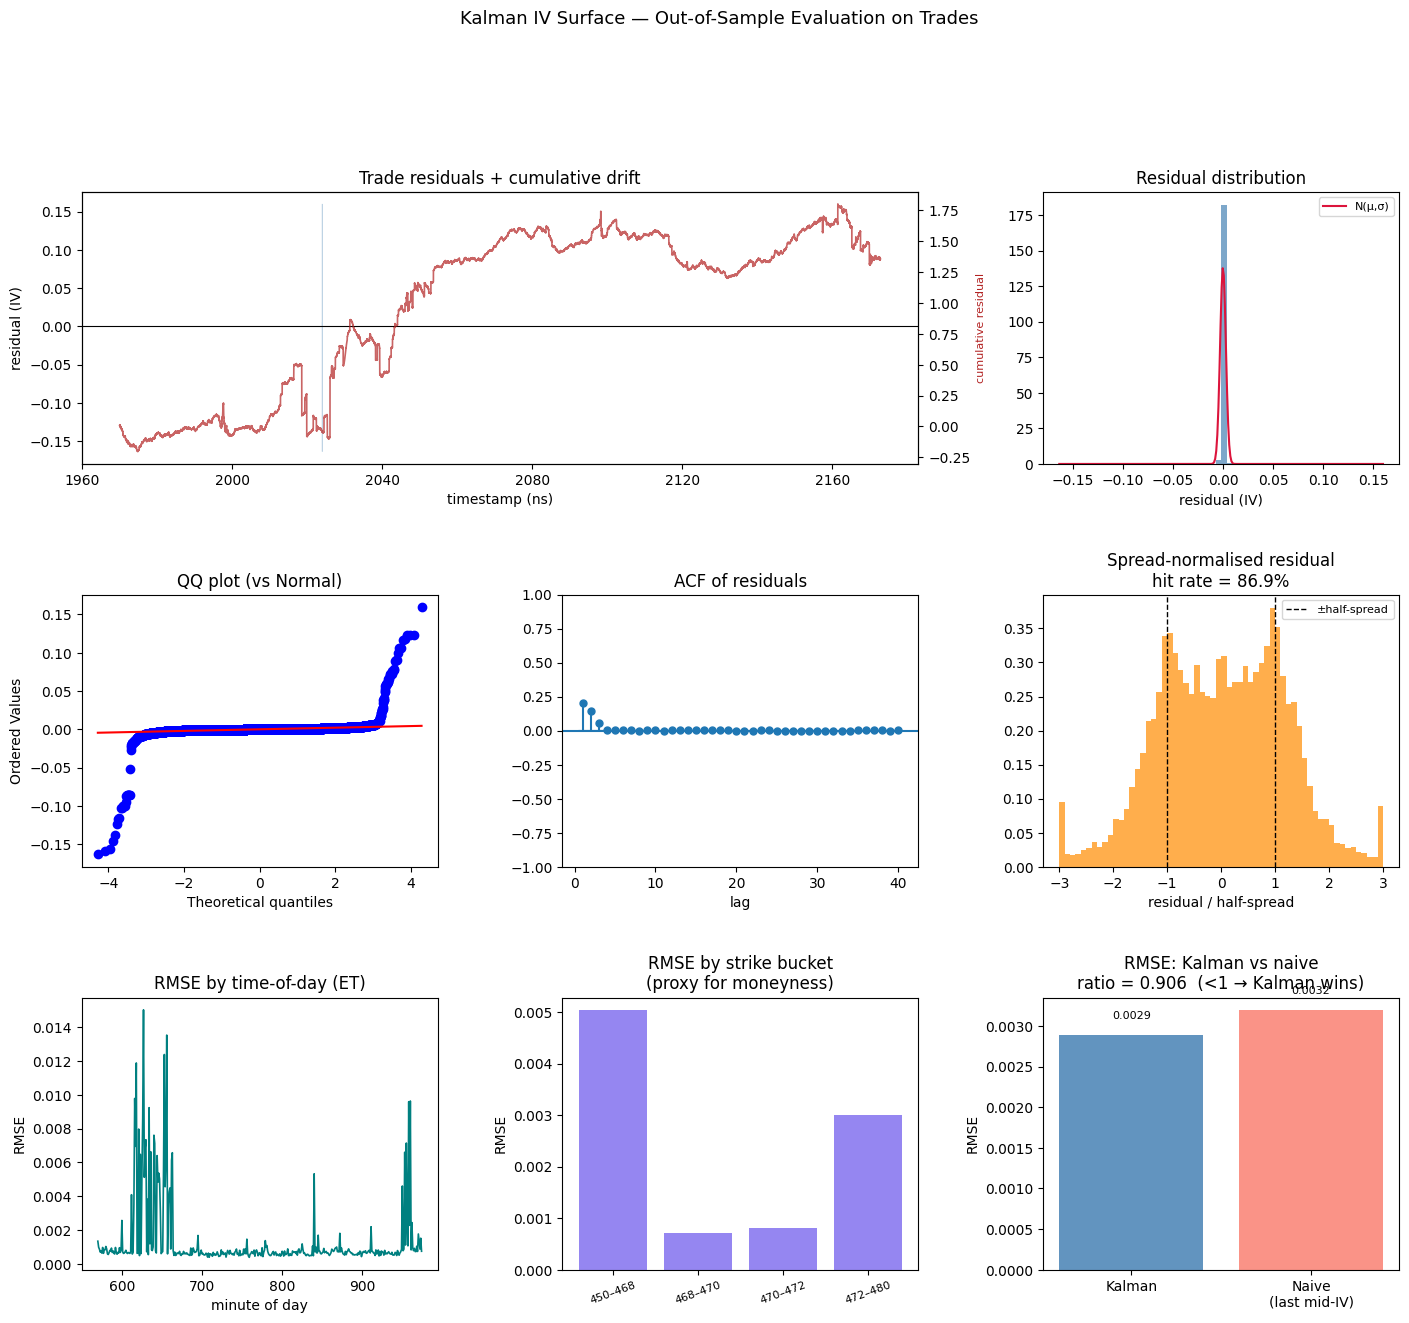

RMSE                 0.00289
MAE                  0.00063
Bias                 0.00002
Hit rate             86.9%
Naive RMSE           0.00319
RMSE ratio           0.906  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
        lb_stat  lb_pvalue
10  5065.423291        0.0
20  5079.353222        0.0


In [14]:
from iv_evaluation import evaluate_kalman_iv

metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)